# Fase 3 — Preparação dos Dados

Regras do projeto:
1. Separação temporal: treino é passado, teste é futuro (últimos 28 dias). Nada é embaralhado.
2. Toda feature existe 28 dias antes do dia previsto (lag ≥ 28; janelas móveis terminam em t − 28). Exceção: calendário promocional.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.dados import carregar_demanda
from src.preparacao import H, PRODUTOS_DESCONTINUADOS, remover_descontinuados, serie_produto, ponto_de_corte, separar_treino_teste

SEED = 42
np.random.seed(SEED)
RAIZ = Path.cwd().parent
CAMINHO_FIGURAS = RAIZ / "relatorios" / "figuras"
PRODUTO = "P0131"

## 1. Filtro de ciclo de vida

In [2]:
demanda = carregar_demanda()
painel = remover_descontinuados(demanda)

print(f"Antes:  {demanda['produto'].nunique()} produtos | {len(demanda):,} linhas")
print(f"Depois: {painel['produto'].nunique()} produtos | {len(painel):,} linhas")
print(f"Removidos: {sorted(set(demanda['produto']) - set(painel['produto']))} | {len(demanda) - len(painel):,} linhas")
print(f"Descontinuados ainda no painel: {painel['produto'].isin(PRODUTOS_DESCONTINUADOS).sum()}")
print(f"Nulos na coluna alvo (unidades): {painel['unidades'].isna().sum()}")

painel.to_csv(RAIZ / "dados" / "processados" / "painel_sem_descontinuados.csv", index=False)

Antes:  30 produtos | 30,849 linhas
Depois: 27 produtos | 27,883 linhas
Removidos: ['P0051', 'P0079', 'P0438'] | 2,966 linhas
Descontinuados ainda no painel: 0
Nulos na coluna alvo (unidades): 0


## 2 e 3. Horizonte, corte e separação do P0131

In [3]:
serie_p0131 = serie_produto(painel, PRODUTO)
corte = ponto_de_corte(serie_p0131)
treino, teste = separar_treino_teste(serie_p0131)

print(f"H = {H}")
print(f"Última data da série: {serie_p0131.index.max().date()}")
print(f"Ponto de corte:       {corte.date()}")
print()
print(f"Treino: {treino.index.min().date()} a {treino.index.max().date()} | {len(treino)} dias")
print(f"Teste:  {teste.index.min().date()} a {teste.index.max().date()} | {len(teste)} dias")
print()
print(f"Sobreposição treino/teste: {len(treino.index.intersection(teste.index))} dias")
print(f"Treino + teste = série inteira: {len(treino) + len(teste) == len(serie_p0131)}")
print(f"Nulos em unidades — treino: {treino['unidades'].isna().sum()} | teste: {teste['unidades'].isna().sum()}")

H = 28
Última data da série: 2019-10-31
Ponto de corte:       2019-10-03

Treino: 2017-01-02 a 2019-10-03 | 1005 dias
Teste:  2019-10-04 a 2019-10-31 | 28 dias

Sobreposição treino/teste: 0 dias
Treino + teste = série inteira: True
Nulos em unidades — treino: 0 | teste: 0


## 4. Série inteira com treino e teste

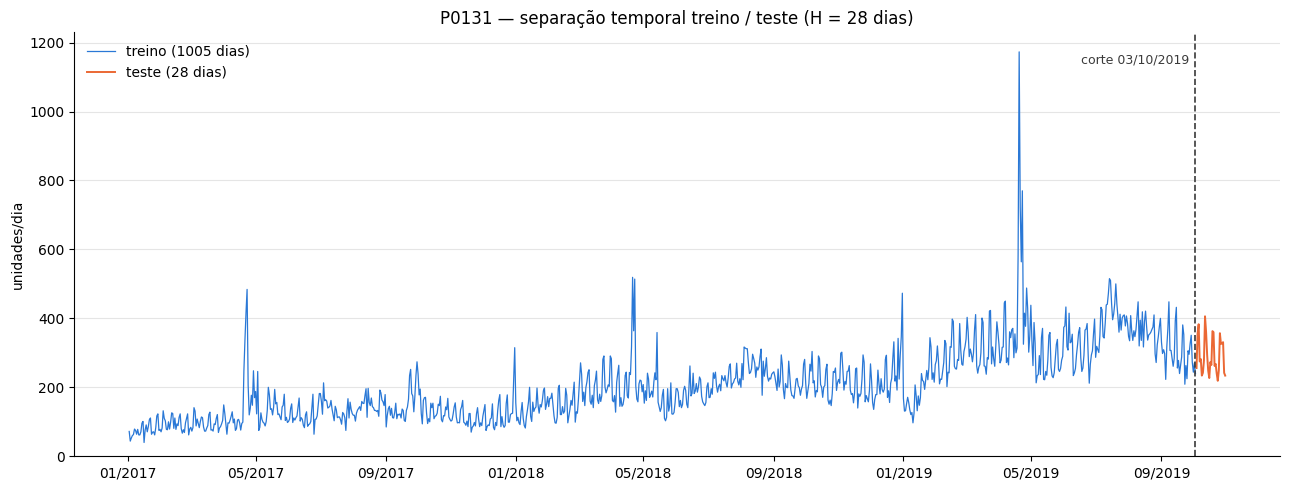

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(treino.index, treino["unidades"], color="#2a78d6", lw=0.9, label=f"treino ({len(treino)} dias)")
ax.plot(teste.index, teste["unidades"], color="#eb6834", lw=1.4, label=f"teste ({len(teste)} dias)")
ax.axvline(corte, color="#3a3a3a", lw=1.2, ls="--")
ax.text(corte - pd.Timedelta(days=6), ax.get_ylim()[1] * 0.95, f"corte {corte:%d/%m/%Y}", ha="right", va="top", fontsize=9, color="#3a3a3a")
ax.set_title(f"{PRODUTO} — separação temporal treino / teste (H = {H} dias)")
ax.set_ylabel("unidades/dia")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(CAMINHO_FIGURAS / "03_P0131_treino_teste.png", dpi=130)
plt.show()